In [1]:
import os
import shutil
import torch
import torch.nn as nn #for Section 7
from torch.utils.data import DataLoader
from torch.utils.data import Subset, random_split # For Section 6
from torchvision import datasets, transforms, models
from torch.optim import AdamW #for Section 7
from tqdm import tqdm
from torch.cuda import amp
from torch.utils.data import Dataset
import json
from PIL import Image
from torchvision import datasets, transforms
import kagglehub

import matplotlib.pyplot as plt #for section 5
import torchvision.transforms.functional as F # for section #5

#from sklearn.model_selection import train_test_split

#from torch.cuda.amp import autocast, GradScaler #for section #7
#change because
#FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
from torch import autocast #for section 7
from torch.amp import GradScaler # for section 7


# Use current working directory as project root
PROJECT_ROOT = os.getcwd()

# Define the data folder relative to the project root
DATA_DIR = os.path.join(PROJECT_ROOT, "data", "flower_data")
TRAIN_DIR = os.path.join(DATA_DIR, "train")
VALID_DIR = os.path.join(DATA_DIR, "valid")
TEST_DIR  = os.path.join(DATA_DIR, "test")
os.makedirs(DATA_DIR, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)

# -------- params (tweak for GPU) ---------- #this is for section 7 #and very useful for SEction 10
# General parameters
NUM_CLASSES = 102 #this one have to upsize to 102 later to fit our full dataset
BATCH_SIZE = 32 #change later to compatible with my rtx3070
ACCUMULATION_STEPS = 4 #change later
NUM_EPOCHS = 30 #Section 10 #change later
LEARNING_RATE = 3e-4 # change later
WEIGHT_DECAY = 1e-4 #change later
NUM_WORKERS = 8 #change later
MODEL_ARCHITECTURE = "Resnet50"


# Save directory for models/checkpoints
SAVE_DIR = os.path.join(PROJECT_ROOT, "checkpoints")
os.makedirs(SAVE_DIR, exist_ok=True)

C:\Users\chuaw\anaconda3\envs\DLSem3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project root: C:\Users\chuaw\Projects\DLSem3_Assignment1
Data directory: C:\Users\chuaw\Projects\DLSem3_Assignment1\data\flower_data


In [2]:
#identify what device is using, and pass to the next function later, it is fine to use cpu, but optimally better performance will use gpu
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [3]:
# Download dataset if not already present
if not os.listdir(DATA_DIR):  # folder is empty
    print("Dataset not found. Downloading via KaggleHub...")
    tmp_path = kagglehub.dataset_download("waseemalastal/the-oxford-flowers-102-dataset")
    # Copy everything to our project folder
    shutil.copytree(tmp_path, DATA_DIR, dirs_exist_ok=True)
    
else:
    print("Dataset already exists in:", DATA_DIR)
print("Dataset should be complete now")

Dataset already exists in: C:\Users\chuaw\Projects\DLSem3_Assignment1\data\flower_data
Dataset should be complete now


# Compulsory to run the next cell
> Run the next cell

In [4]:
# Load cat_to_name mapping
with open(os.path.join(DATA_DIR, "cat_to_name.json"), "r") as f:
    cat_to_name = json.load(f)

# Transforms
transform = transforms.Compose([
    transforms.Resize((224, 224)), #i think this is warping, basically stretches the image to fit 224 224, but not sure, dont think this is adding padding
    transforms.ToTensor(),
])
class TestDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        # List all image files
        self.image_files = sorted([f for f in os.listdir(root_dir)
                                   if f.lower().endswith(('.png', '.jpg', '.jpeg'))])

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img_path = os.path.join(self.root_dir, self.image_files[idx])
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        # Return image and filename (no label)
        return image, self.image_files[idx]

# Example usage chatgpt
# transform = transforms.Compose([
#     transforms.Resize((224, 224)),
#     transforms.ToTensor(),
# ])



# Datasets
train_dataset = datasets.ImageFolder(root=os.path.join(DATA_DIR, "train"), transform=transform)
valid_dataset = datasets.ImageFolder(root=os.path.join(DATA_DIR, "valid"), transform=transform)
test_dataset = TestDataset(root_dir=os.path.join(DATA_DIR, "test"), transform=transform)

In [5]:
# DataLoaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=32)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# Map numeric labels to class names
def decode_label(label):
    folder_name = train_dataset.classes[label]  # e.g., '1', '2', ...
    return cat_to_name.get(folder_name, folder_name)

# Example
print(f"Number of classes: {len(train_dataset.classes)}")
print(f"First 5 class names: {[decode_label(i) for i in range(5)]}")
print(f"Training samples: {len(train_dataset)}")
print(f"The following is test images")
for images, filenames in test_loader:
    print(filenames)  # shows original file names
    break

Number of classes: 102
First 5 class names: ['pink primrose', 'globe thistle', 'blanket flower', 'trumpet creeper', 'blackberry lily']
Training samples: 6552
The following is test images
('image_00005.jpg', 'image_00006.jpg', 'image_00024.jpg', 'image_00025.jpg', 'image_00029.jpg', 'image_00050.jpg', 'image_00060.jpg', 'image_00065.jpg', 'image_00092.jpg', 'image_00099.jpg', 'image_00114.jpg', 'image_00116.jpg', 'image_00132.jpg', 'image_00176.jpg', 'image_00177.jpg', 'image_00187.jpg', 'image_00191.jpg', 'image_00202.jpg', 'image_00203.jpg', 'image_00204.jpg', 'image_00212.jpg', 'image_00222.jpg', 'image_00239.jpg', 'image_00248.jpg', 'image_00251.jpg', 'image_00258.jpg', 'image_00260.jpg', 'image_00277.jpg', 'image_00282.jpg', 'image_00284.jpg', 'image_00288.jpg', 'image_00291.jpg')


In [6]:
DATA_ROOT = train_dataset
TARGET_SIZE = (34,34)
TARGET_CHANNELS = 3

SAMPLE_IMAGE_PATH = train_dataset[0][0]

SAMPLE_IMAGE_PATH

tensor([[[0.0039, 0.0275, 0.1725,  ..., 0.2118, 0.2353, 0.2314],
         [0.0039, 0.0314, 0.1490,  ..., 0.2392, 0.2392, 0.2353],
         [0.0039, 0.0353, 0.0863,  ..., 0.2431, 0.2392, 0.2392],
         ...,
         [0.0039, 0.0000, 0.0000,  ..., 0.0392, 0.0353, 0.0314],
         [0.0078, 0.0039, 0.0078,  ..., 0.0471, 0.0353, 0.0314],
         [0.0078, 0.0039, 0.0078,  ..., 0.0471, 0.0353, 0.0314]],

        [[0.2039, 0.1725, 0.2431,  ..., 0.2392, 0.2627, 0.2588],
         [0.1961, 0.1765, 0.2275,  ..., 0.2627, 0.2588, 0.2588],
         [0.1843, 0.1765, 0.1725,  ..., 0.2627, 0.2627, 0.2627],
         ...,
         [0.0706, 0.0667, 0.0627,  ..., 0.1451, 0.1412, 0.1373],
         [0.0706, 0.0667, 0.0588,  ..., 0.1451, 0.1333, 0.1255],
         [0.0706, 0.0667, 0.0588,  ..., 0.1451, 0.1333, 0.1255]],

        [[0.0902, 0.1020, 0.2275,  ..., 0.2078, 0.2314, 0.2275],
         [0.0941, 0.1137, 0.2118,  ..., 0.2353, 0.2314, 0.2275],
         [0.0902, 0.1216, 0.1608,  ..., 0.2275, 0.2275, 0.

In [7]:
SAMPLE_IMAGE_PATH.shape

torch.Size([3, 224, 224])

In [8]:
# Display Original Image
# def display_original_image(sample_path):
#     """Loads and displays the starting image for reference."""
#     print("\n0. Original Image for Reference...")
#     try:
#         # Check if the file exists before attempting to open
#         if not os.path.exists(sample_path):
#             print(f"   -> WARNING: File not found at {sample_path}. Skipping display.")
#             return

#         img = Image.open(sample_path)

#         plt.figure(figsize=(4, 4))
#         plt.imshow(img)
#         plt.title(f"Original Image ({img.size[0]}x{img.size[1]})")
#         plt.axis('off')
#         print(f"   -> Image loaded successfully. Size: {img.size[0]}x{img.size[1]}, Mode: {img.mode}")
#         plt.show() # Display the image

#     except Exception as e:
#         print(f"   -> ERROR loading original image: {e}")

# display_original_image(SAMPLE_IMAGE_PATH)

In [9]:
#section 5
def display_original_image(sample_path):
    print("\n0. Original Image for Reference")
    try:
        if isinstance(sample_path, str):
            if not os.path.exists(sample_path):
                print(f"   -> WARNING, FILE NOT FOUND AT {sample_path}. Skipping Display")
                return
            img = Image.open(sample_path).convert("RGB")
            title = (f" Image size from {sample_path}= (height - {img.size[0]})x (width - {img.size[1]})")
        elif isinstance(sample_path, torch.Tensor):
            img = F.to_pil_image(sample_path)
            img_channel, img_height, img_width = sample_path.shape
            title = (f" Img is tensor img, (channel = {img_channel}, height = {img_height}, width = {img_width})")
        else:
            print(f" the image path must be a file path or a tensor, lol noob try again")
            return
        plt.figure(figsize = (4,4))
        plt.imshow(img)
        plt.title(title)
        plt.axis("off")
        print(f"image loaded and displayed sucessfully")
        plt.show()
                 
    except Exception as e:
        print(f"sunimasei, error loading original image : {e}")
         


0. Original Image for Reference
image loaded and displayed sucessfully


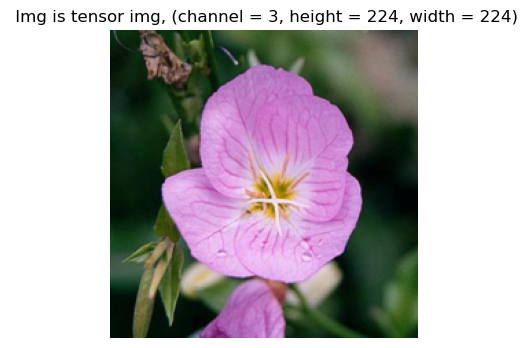

In [10]:
display_original_image(SAMPLE_IMAGE_PATH)

# splitting dataset (my understanding)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)<br>
not considering train_test_split because of this is Pytorch dataset and it is organized into folders<br>
instead, i am using an alternative, which works similiarly to traintest split but without the randomstate ish. should be a pytorch function<br>
<br>
while i am considering pytorch alternative, i noticed that the dataset already splitted the data into training and valid folders, which means
i dont have to perform train_test_split<br>
<br>
<br>
The alternative i considered and found is extra for our project :<br>
<br>
train_size = int(0.8 * len(dataset))<br>
valid_size = len(dataset) - train_size<br>
<br>
train_dataset, valid_dataset = random_split(dataset, [train_size, valid_size])<br>

# PyTorch philosophy (chatgpt clarification)

In PyTorch, we don’t usually extract X_train and y_train into variables.<br>
We keep them inside Dataset or DataLoader because:<br>
<br>
images can be large — you don’t want to load them all into memory at once,<br>
<br>
PyTorch’s DataLoader handles batching, shuffling, and preprocessing efficiently.<br>


In [11]:
#section 6
"""
for X_batch, y_batch in train_loader:
    #empty for now, just to understand the concept, if need use can uncomment later
"""

'\nfor X_batch, y_batch in train_loader:\n    #empty for now, just to understand the concept, if need use can uncomment later\n'

In [12]:
#section 7

#define the build model so that later can change model if want
print("Building (ResNet50) model...")
def build_model(num_classes, pretrained=True, freeze_backbone=True):
    model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT if pretrained else None)
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, num_classes)

    if freeze_backbone:
        for name, param in model.named_parameters():
            if "fc" not in name:
                param.requires_grad = False

    return model.to(device)

Building (ResNet50) model...


# later if want to use model
>>>
    model = build_model(NUM_CLASSES)<br>
# later need to change the freeze_backbone once the model is stabled, because:
> When you freeze the backbone (chatgpt):
<br>
> for name, param in model.named_parameters():<br>
>    if "fc" not in name:<br>
>        param.requires_grad = False<br>
<br>
<br>
>you’re telling PyTorch:<br>

>"Don’t update the weights of the convolutional layers during training — only train the final classification layer (fc)."<br>
<br>
>Why do this?<br>
<br>
>Because:<br>
<br>
>The pretrained backbone already learned general image features.<br>
<br>
>You just need to teach the final layer to map those features to your own classes (1–5, or 1–102 later).<br>
<br>
>So effectively:<br>
 >- Frozen backbone → only the new final layer learns.<br>
 >- Fast training<br>
 >- Needs less GPU<br>
 >- Slightly less accurate, but good baseline.<br>
 >- Unfrozen backbone → entire network fine-tunes on your dataset.<br>
 >- Slower, more GPU, but more accurate if dataset is large enough.<br>


In [13]:
#section 8
model = build_model(num_classes=NUM_CLASSES, pretrained=True, freeze_backbone=True)
print(model)
print("Model Built Sucessfully lets go!")

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

# Define my loss, optimizer, and scaler

In [14]:
# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

# Mixed precision scaler
scaler = GradScaler()

In [15]:
print(model.layer1)


Sequential(
  (0): Bottleneck(
    (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (downsample): Sequential(
      (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
  )
  (1): Bottleneck(
    (conv1): Conv2d(256, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (conv2): Conv2d(64, 64, ke

In [16]:
#checking my data again
for X, y in train_loader:
    print("Batch X shape:", X.shape)
    print("Batch y shape:", y.shape)
    break


Batch X shape: torch.Size([32, 3, 224, 224])
Batch y shape: torch.Size([32])


In [17]:
#Checking data also
# all_labels = [y for _, y in train_dataset]
# print("Min label:", min(all_labels))
# print("Max label:", max(all_labels))
# print("Number of classes detected:", len(train_dataset.classes))
# print("train_dataset.classes:", train_dataset.classes)


# Section 9: Small Sanity Check


In [18]:
#Section 9

# This section runs one batch through the model
# Get a single batch of data from DataLoader
try:
    X_batch, y_batch = next(iter(train_loader))

    # Move the data to your GPU (since your model is on the GPU)
    X_batch = X_batch.to(device)
    y_batch = y_batch.to(device)

    # --- This is the Forward Pass ---
    # Get the model's predictions for the batch
    outputs = model(X_batch)

    print("Lets goooo Sanity successful!")
    print(f"Input batch shape: {X_batch.shape}")
    print(f"Output (predictions) shape: {outputs.shape}")
    print(f"COrrect output, The output shape is [Batch Size, Number of Classes] -> [{BATCH_SIZE}, {NUM_CLASSES}].")

except Exception as e:
    print(f"Sanity Check, error occured at: {e}")

Lets goooo Sanity successful!
Input batch shape: torch.Size([32, 3, 224, 224])
Output (predictions) shape: torch.Size([32, 102])
COrrect output, The output shape is [Batch Size, Number of Classes] -> [32, 102].


# Section 10: Training the model

In [19]:
#Section 10

#chatgpt starts here-----------------------
# A dictionary to store your hyperparameters
HPARAMS = {
    'learning_rate': LEARNING_RATE,
    'epochs': NUM_EPOCHS,
    'batch_size': BATCH_SIZE,
    'accumulation_steps': ACCUMULATION_STEPS,
    'weight_decay': WEIGHT_DECAY,
    'architecture': MODEL_ARCHITECTURE,
    'num_workers' : NUM_WORKERS
}
history = {
    'train_loss': [],
    'val_loss': [],
    'val_acc': []
}

best_val_accuracy = 0.0  # Initialize with a low value

#chatgpt ends here --------------------------

for epoch in range(NUM_EPOCHS):
    model.train() # put model in training mode
    train_loss = 0.0 #Check definition later, dont understand why this is for

    #Progress bar to show when running
    # YOUR ASSISTANT'S NOTE: Added enumerate() to get the batch index 'i'. This fixes the crash.
    train_loop = tqdm(enumerate(train_loader), total=len(train_loader), leave=True)
    train_loop.set_description(f"Epoch {epoch+1}/{NUM_EPOCHS} [Training]")

    # YOUR ASSISTANT'S NOTE: Clear gradients ONCE before the accumulation cycle begins.
    optimizer.zero_grad()
    
    # YOUR ASSISTANT'S NOTE: The loop now correctly provides the index 'i' and the batch.
    for i, (X_batch, y_batch) in train_loop:
        # now this will pass the training batch to your device, device is automatically determine
        # above, CPU for cpu, and cuda for GPU, optimally, gpu will be way more faster, i am using
        # gpu
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        #1 forward pass
        # i think this is the same as model.fit(X_train), but i am not sure, probably tensor doesnt need fit
        outputs = model(X_batch)

        #2 Calculate loss
        loss = criterion(outputs, y_batch)
        loss = loss / ACCUMULATION_STEPS # this is to utilize our accumulation steps
        
        #3 Backward pass
        # YOUR ASSISTANT'S NOTE: This call now SUMS the gradients because we haven't cleared them yet.
        loss.backward()

        # THIS IS THE IMPORTANT LINE THAT WAS MISSING
        train_loss += loss.item() * ACCUMULATION_STEPS

        # YOUR ASSISTANT'S NOTE: The optimizer only steps and clears gradients here, after enough batches.
        # The incorrect calls from before have been REMOVED.
        if (i + 1) % ACCUMULATION_STEPS == 0:
            optimizer.step()
            optimizer.zero_grad()

    #4 Validation
    model.eval()   # eval for evaluation ,this put the model into evaluation mode
    valid_loss = 0.0
    correct = 0
    total = 0

    # validation progress bar
    val_loop = tqdm(valid_loader, leave=True)
    val_loop.set_description(f"Epoch {epoch+1}/{NUM_EPOCHS} [Validation]")

    # dont need to calculate gradient during validation
    #but why?
    with torch.no_grad():
        for X_batch, y_batch in val_loop:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            valid_loss += loss.item()
            
            # Calculate accuracy
            _, predicted = torch.max(outputs.data, 1)
            total += y_batch.size(0)
            correct += (predicted == y_batch).sum().item()
    
    # GEMINI'S NOTE: This entire block below was un-indented.
    # It must run AFTER the validation loop (above) is finished, not inside it.
    
    # Print Epoch Statistics
    avg_train_loss = train_loss / len(train_loader)
    avg_valid_loss = valid_loss / len(valid_loader)
    accuracy = 100 * correct / total
    
    print(f"\nEpoch {epoch+1} Summary:")
    print(f"  -> Average Training Loss: {avg_train_loss:.4f}")
    print(f"  -> Average Validation Loss: {avg_valid_loss:.4f}")
    print(f"  -> Validation Accuracy: {accuracy:.2f}%\n")
    history['train_loss'].append(avg_train_loss)
    history['val_loss'].append(avg_valid_loss)
    history['val_acc'].append(accuracy)
    
    if accuracy > best_val_accuracy:
        best_val_accuracy = accuracy
        
        # Create a checkpoint dictionary
        checkpoint = {
            'epoch': epoch + 1,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'best_val_accuracy': best_val_accuracy,
            'hyperparameters': HPARAMS
        }
        
        # Save the checkpoint
        torch.save(checkpoint, 'best_model_checkpoint.pth')
        
        print(f"huhu ! Checkpoint saved at epoch {epoch + 1} with new best accuracy: {best_val_accuracy:.2f}%")

print("The training is successfully completed")

Epoch 1/30 [Validation]: 100%|█████████████████████████████████████████████████████████| 26/26 [00:07<00:00,  3.26it/s]



Epoch 1 Summary:
  -> Average Training Loss: 4.2355
  -> Average Validation Loss: 3.9145
  -> Validation Accuracy: 19.44%

huhu ! Checkpoint saved at epoch 1 with new best accuracy: 19.44%


Epoch 2/30 [Validation]: 100%|█████████████████████████████████████████████████████████| 26/26 [00:07<00:00,  3.66it/s]



Epoch 2 Summary:
  -> Average Training Loss: 3.5756
  -> Average Validation Loss: 3.3855
  -> Validation Accuracy: 44.01%

huhu ! Checkpoint saved at epoch 2 with new best accuracy: 44.01%


Epoch 3/30 [Validation]: 100%|█████████████████████████████████████████████████████████| 26/26 [00:06<00:00,  3.94it/s]



Epoch 3 Summary:
  -> Average Training Loss: 3.0353
  -> Average Validation Loss: 2.8993
  -> Validation Accuracy: 62.59%

huhu ! Checkpoint saved at epoch 3 with new best accuracy: 62.59%


... (50 outputs left out)

Epoch 29/30 [Validation]: 100%|████████████████████████████████████████████████████████| 26/26 [00:06<00:00,  4.12it/s]



Epoch 29 Summary:
  -> Average Training Loss: 0.2881
  -> Average Validation Loss: 0.5658
  -> Validation Accuracy: 92.42%

huhu ! Checkpoint saved at epoch 29 with new best accuracy: 92.42%


Epoch 30/30 [Validation]: 100%|████████████████████████████████████████████████████████| 26/26 [00:06<00:00,  4.15it/s]



Epoch 30 Summary:
  -> Average Training Loss: 0.2723
  -> Average Validation Loss: 0.5502
  -> Validation Accuracy: 92.54%

huhu ! Checkpoint saved at epoch 30 with new best accuracy: 92.54%
The training is successfully completed


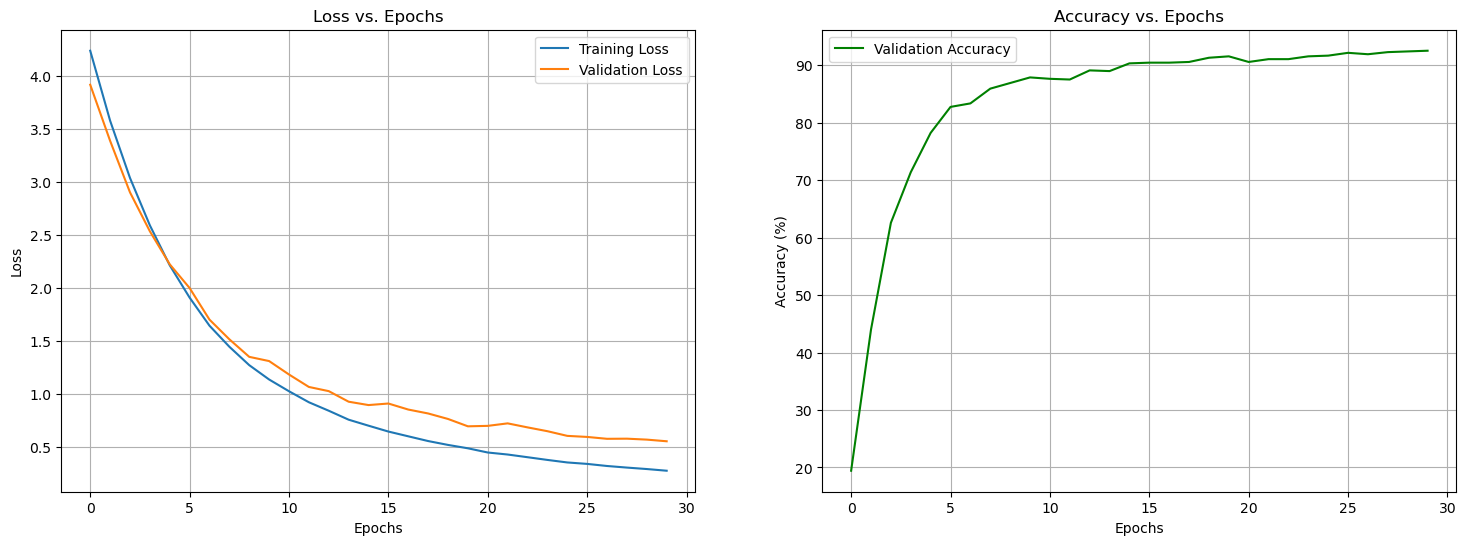

In [24]:
#plotting the graph to show training progress
def plot_training_history(history):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

    # this one will plot training and valid loss
    ax1.plot(history['train_loss'], label='Training Loss')
    ax1.plot(history['val_loss'], label='Validation Loss')
    ax1.set_title('Loss vs. Epochs')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax1.grid(True)

    # this one will plot validation accuracy over each epoch
    ax2.plot(history['val_acc'], label='Validation Accuracy', color='green')
    ax2.set_title('Accuracy vs. Epochs')
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('Accuracy (%)')
    ax2.legend()
    ax2.grid(True)

    plt.show()

plot_training_history(history)

In [20]:
print(f"best value of accuracy currently --- {best_val_accuracy:.2f}%")

best value of accuracy currently --- 92.54%


In [25]:
# maybe can make the training into a function and then call the function
# maybe can make saving the training a function and save the thing
# my idea is to save the model parameters, trained_models, and the hyperparameters
# used at the same time, and then it will compare with the last best accuracy model, and
# then i can decide how to change the parameters

# Save the model's learned parameters to a file
# can change the number here so it saves as new file
torch.save(model.state_dict(), 'trained_model2.pth')

In [22]:
#what is training loss
#what is validation loss
# what is validation accuracy

#import to csv file to save the parameters and the model

#add graphs, evaluation graphs

#confusion matrix : when testing on multiple images so it is effective